# EDA 5 · Audience: languages, spending, shared players

1. **RU / EN / ZH**: how the audiences differ in 👍 share, hours played, review habits; where one language rates a game very differently.
2. **What each language writes about**: types among all and among 👎 reviews.
3. **Spending power proxies**: regional prices (relative, there are no exchange rates), hours played, quick reviews within the refund window. The Steam API no longer returns library size.
4. **Shared audience**: games are linked by Steam accounts that reviewed both (a graph for the models' game features).
5. **Competitor releases**: what happens to a game's reviews when a game with a shared audience comes out.

In [1]:
import textwrap

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from scipy.cluster.hierarchy import leaves_list, linkage

from src.config import CONFIG, FEATURES_DIR, TOPIC_NOISE, TOPIC_SHORT, game_names
from src.db import read
from src.features.audience import audience_overlap, neighbours
from src.features.daily import collection, daily_series
from src.features.events import event_study
from src.text.topics import topic_names
from src.viz.charts import LANG_COLORS, SERIES_COLOR, use_style

use_style()
LANGS = CONFIG.reviews.languages
MIN_REVIEWS = 300   # a game's language counts in comparisons with at least this many kept reviews

In [2]:
names = game_names()
collected = collection()
games = collected.index[collected["complete"].ne(False)]
profile = read.language_profile(games)
profile["game"] = profile["appid"].map(names)
profile = profile[profile["language"].isin(LANGS)]
print(f"{profile['appid'].nunique()} games, {profile['n'].sum():,} kept reviews")

62 games, 25,025,860 kept reviews


## 1. RU / EN / ZH audiences

Medians over games (each game counts once, so Counter-Strike 2 does not decide the result), only languages with at least `MIN_REVIEWS` reviews in a game.

In [3]:
enough = profile[profile["n"] >= MIN_REVIEWS]
columns = ["positive", "hours_at_review", "hours_total", "author_reviews", "text_length", "under_2h", "free"]
overview = enough.groupby("language")[columns].median().reindex(LANGS)
overview.insert(0, "games", enough.groupby("language").size())
overview.insert(1, "reviews", profile.groupby("language")["n"].sum())
overview.style.format({"reviews": "{:,.0f}", "positive": "{:.0%}", "hours_at_review": "{:.0f}", "hours_total": "{:.0f}",
                       "author_reviews": "{:.0f}", "text_length": "{:.0f}", "under_2h": "{:.0%}", "free": "{:.1%}"}).set_caption(
    "under_2h: written within 2 hours of play (Steam's refund window); free: got the game for free")

,games,reviews,positive,hours_at_review,hours_total,author_reviews,text_length,under_2h,free
language,,,,,,,,,
english,61,"14,162,545",89%,33,72,8,53,4%,1.4%
russian,61,"6,036,625",87%,26,59,7,47,6%,1.8%
schinese,60,"4,584,807",82%,21,49,5,15,5%,0.7%
tchinese,53,"241,883",87%,38,70,7,15,4%,0.8%


**👍 share per game and language**, sorted by the English share. Long horizontal spans are games where the audiences disagree.

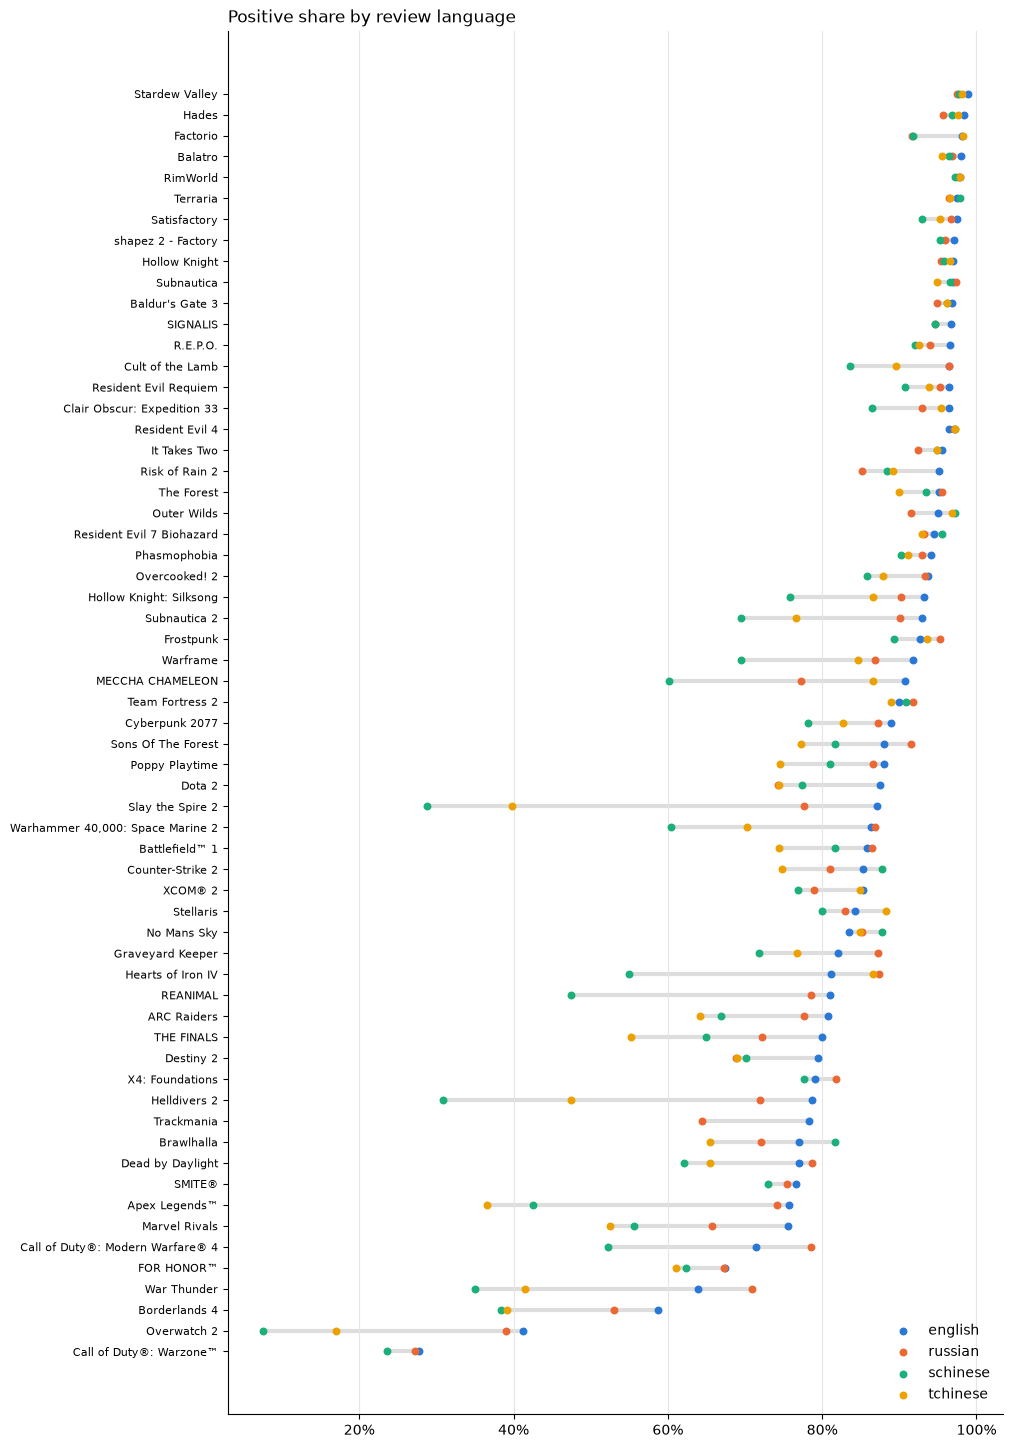

In [4]:
wide = enough.pivot(index="game", columns="language", values="positive").reindex(columns=LANGS)
wide = wide.sort_values("english")
fig, ax = plt.subplots(figsize=(10, 0.27 * len(wide) + 1.5))
ax.hlines(range(len(wide)), wide.min(axis=1), wide.max(axis=1), color="#dddddd", linewidth=3, zorder=0)
for language in LANGS:
    ax.scatter(wide[language], range(len(wide)), s=22, color=LANG_COLORS[language], label=language, zorder=2)
ax.set_yticks(range(len(wide)), wide.index, fontsize=8)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
ax.set_title("Positive share by review language", loc="left");

In [5]:
gaps = pd.DataFrame({f"{lang} − english": wide[lang] - wide["english"] for lang in ["russian", "schinese"]})
print("Games where Russian or Chinese players rate most differently from English ones (points)")
display(pd.concat([gaps.nsmallest(8, "russian − english"), gaps.nsmallest(8, "schinese − english"),
                   gaps.nlargest(5, "schinese − english")]).drop_duplicates()
        .style.format("{:+.0%}", na_rep="").background_gradient(cmap="RdBu", vmin=-0.4, vmax=0.4))

Games where Russian or Chinese players rate most differently from English ones (points)


,russian − english,schinese − english
game,,
Trackmania,-14%,
MECCHA CHAMELEON,-14%,-31%
Dota 2,-13%,-10%
Destiny 2,-11%,-9%
Risk of Rain 2,-10%,-7%
Marvel Rivals,-10%,-20%
Slay the Spire 2,-10%,-58%
THE FINALS,-8%,-15%
Helldivers 2,-7%,-48%


## 2. What each language writes about

Share of each review type among a language's 👎 reviews (too short and no clear topic left out), pooled over games. 

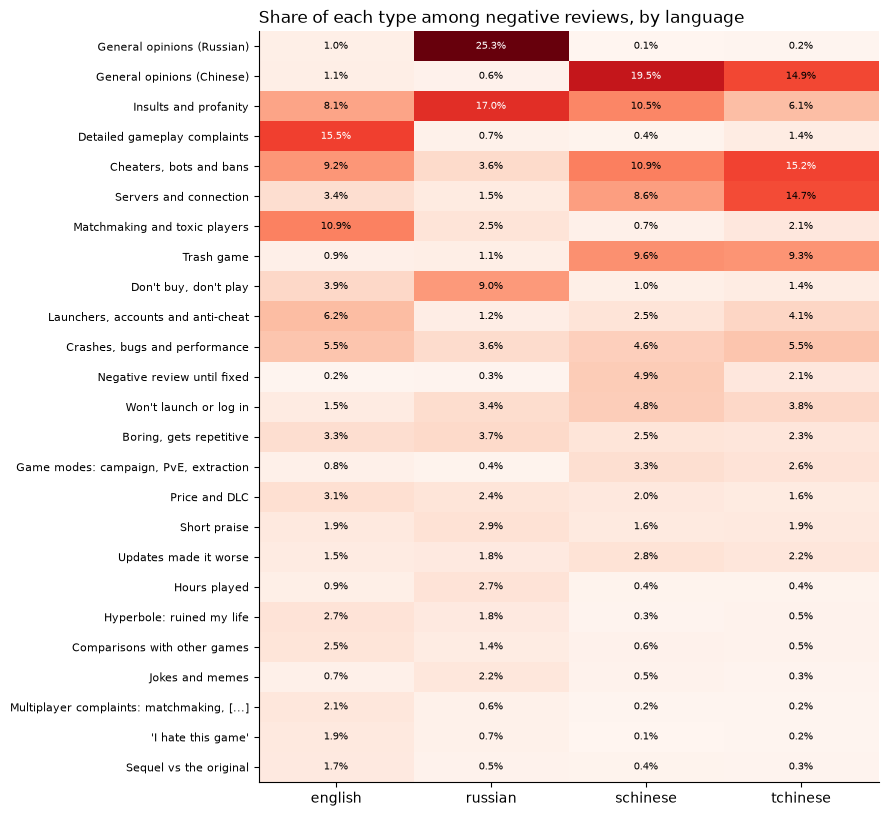

In [6]:
labels = topic_names(read.topics(), with_id=False)
by_topic = read.topics_by_language(games)
by_topic = by_topic[by_topic["language"].isin(LANGS) & ~by_topic["topic_id"].isin([TOPIC_SHORT, TOPIC_NOISE])]
by_topic["type"] = by_topic["topic_id"].map(labels)
negative = by_topic[~by_topic["voted_up"].astype(bool)].groupby(["type", "language"])["n"].sum().unstack(fill_value=0)[LANGS]
negative_share = negative / negative.sum()
top = negative_share.loc[negative_share.max(axis=1).sort_values(ascending=False).index[:25]]

fig, ax = plt.subplots(figsize=(8, 0.33 * len(top) + 1.5))
ax.imshow(top, cmap="Reds", aspect="auto")
for (i, j), v in np.ndenumerate(top.to_numpy()):
    ax.text(j, i, f"{v:.1%}", ha="center", va="center", fontsize=7, color="white" if v > 0.6 * top.to_numpy().max() else "black")
ax.set_xticks(range(len(LANGS)), LANGS)
ax.set_yticks(range(len(top)), [textwrap.shorten(s, 45) for s in top.index], fontsize=8)
ax.grid(False)
ax.set_title("Share of each type among negative reviews, by language", loc="left");

**Language-specific types**: types whose share in a language is at least 2× their share in the other languages, among all reviews with a type (at least 0.5% of them) and among 👎 reviews (at least 1%). Often a game reviewed mostly in that language, local problems (servers, translation, prices) or slang.

In [7]:
def language_specific(counts, min_share):
    """Types whose share in a language is at least 2× their share in the other languages."""
    share = counts / counts.sum()
    rows = []
    for lang in ["english", "russian", "schinese"]:
        rest = counts.drop(columns=lang).sum(axis=1)
        ratio = share[lang] / (rest / rest.sum())
        picked = ratio[(ratio >= 2) & (share[lang] >= min_share)].sort_values(ascending=False).head(8)
        rows += [{"language": lang, "type": t, "share": share.loc[t, lang], "vs other languages": r} for t, r in picked.items()]
    return pd.DataFrame(rows).style.format({"share": "{:.1%}", "vs other languages": "{:.1f}×"}).hide(axis="index")


all_reviews = by_topic.groupby(["type", "language"])["n"].sum().unstack(fill_value=0)[LANGS]
print("Among all reviews with a type")
display(language_specific(all_reviews, 0.005))
print("Among 👎 reviews")
display(language_specific(negative, 0.01))

Among all reviews with a type


language,type,share,vs other languages
english,Detailed gameplay complaints,3.5%,18.0×
english,Strong recommendation,21.6%,8.8×
english,Matchmaking and toxic players,2.5%,4.7×
english,"Multiplayer complaints: matchmaking, maps, TTK",0.5%,4.1×
english,'I hate this game',1.2%,4.0×
english,"Launchers, accounts and anti-cheat",2.4%,3.6×
english,Great graphics and story,1.9%,2.7×
english,Comparisons with other games,2.0%,2.2×
russian,General opinions (Russian),19.6%,22.9×
russian,"Don't buy, don't play",3.9%,3.6×


Among 👎 reviews


language,type,share,vs other languages
english,RNG and repetitive gameplay,1.0%,30.8×
english,Detailed gameplay complaints,15.5%,28.3×
english,Strong recommendation,1.3%,10.2×
english,Matchmaking and toxic players,10.9%,7.4×
english,"Multiplayer complaints: matchmaking, maps, TTK",2.1%,5.9×
english,'I hate this game',1.9%,5.7×
english,Sequel vs the original,1.7%,4.0×
english,Hyperbole: ruined my life,2.7%,3.0×
russian,General opinions (Russian),25.3%,40.1×
russian,Gibberish and shouting,1.3%,4.7×


## 3. Spending power proxies

**Regional prices**: Steam prices are in local currency and there are no exchange rates here, so each price is compared with the **median paid game in the same region**. A game at 1.5 in Russia and 1.0 in the US is relatively more expensive for Russian players than other games are. Games not sold in a region have no price there.

games without a price (free or not sold) per region: {'cn': 14, 'ru': 16, 'tw': 15, 'us': 15}


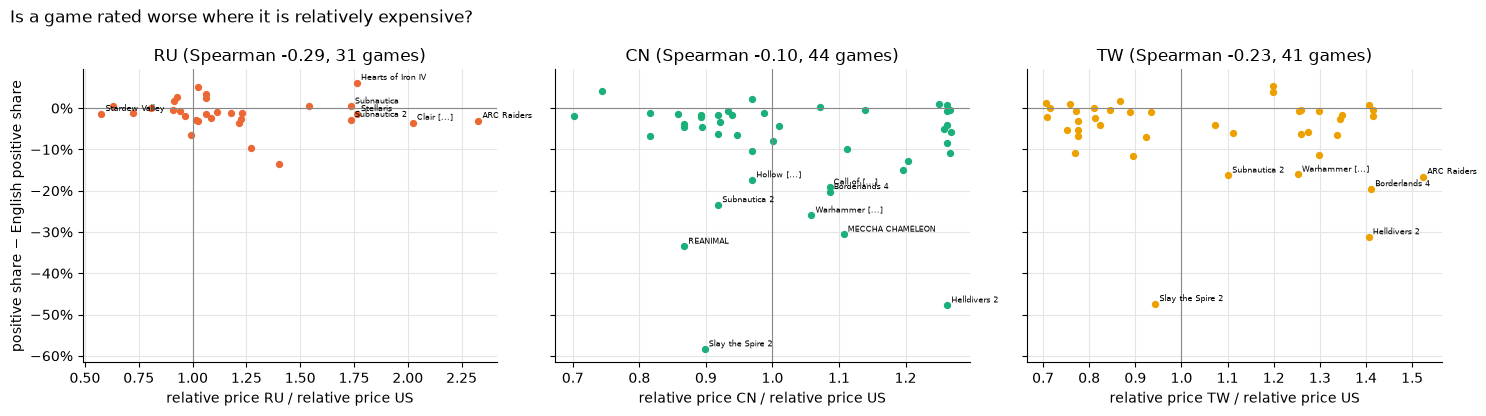

In [8]:
prices = read.prices(games)
paid = prices[prices["price_final"].fillna(0) > 0].copy()
paid["relative"] = paid["price_final"] / paid.groupby("country_code")["price_final"].transform("median")
relative = paid.pivot(index="appid", columns="country_code", values="relative")
not_sold = prices[prices["price_final"].isna() | (prices["currency"].isna())].groupby("country_code")["appid"].nunique()
print("games without a price (free or not sold) per region:", not_sold.to_dict())

lang_of = {"ru": "russian", "cn": "schinese", "tw": "tchinese"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, (country, lang) in zip(axes, lang_of.items(), strict=True):
    x = (relative[country] / relative["us"]).rename("x")
    y = (wide[lang] - wide["english"]).rename(index={v: k for k, v in names.items()}).rename("y")
    both = pd.concat([x, y], axis=1).dropna()
    ax.scatter(both["x"], both["y"], s=18, color=LANG_COLORS[lang])
    for appid, r in both.iterrows():
        if abs(r["y"]) > 0.15 or r["x"] > 1.6 or r["x"] < 0.6:
            ax.annotate(textwrap.shorten(names[appid], 18), (r["x"], r["y"]), fontsize=6, xytext=(3, 2), textcoords="offset points")
    rho = both["x"].corr(both["y"], method="spearman")
    ax.axhline(0, color="#888888", linewidth=0.8)
    ax.axvline(1, color="#888888", linewidth=0.8)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set(title=f"{country.upper()} (Spearman {rho:+.2f}, {len(both)} games)", xlabel=f"relative price {country.upper()} / relative price US")
axes[0].set_ylabel("positive share − English positive share")
fig.suptitle("Is a game rated worse where it is relatively expensive?", x=0.01, ha="left")
fig.tight_layout()

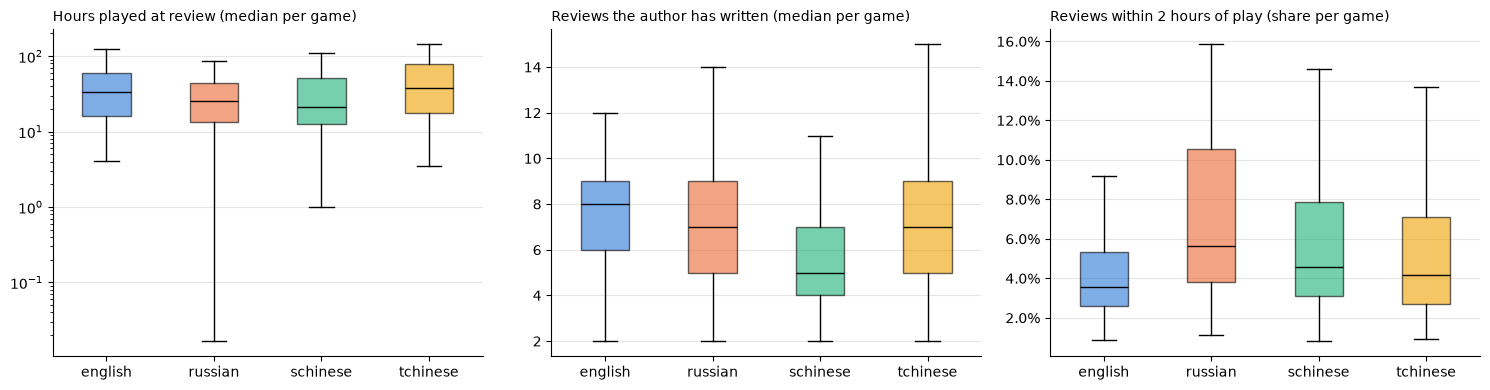

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column, title in zip(axes, ["hours_at_review", "author_reviews", "under_2h"],
                             ["Hours played at review (median per game)", "Reviews the author has written (median per game)",
                              "Reviews within 2 hours of play (share per game)"], strict=True):
    data = [enough.loc[enough["language"] == lang, column].dropna() for lang in LANGS]
    box = ax.boxplot(data, tick_labels=LANGS, patch_artist=True, showfliers=False, medianprops={"color": "black"})
    for patch, lang in zip(box["boxes"], LANGS, strict=True):
        patch.set_facecolor(LANG_COLORS[lang])
        patch.set_alpha(0.6)
    if column == "hours_at_review":
        ax.set_yscale("log")
    if column == "under_2h":
        ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_title(title, loc="left", fontsize=10)
    ax.grid(axis="x", visible=False)
fig.tight_layout()

## 4. Shared audience between games

Two games are linked by the Steam accounts that reviewed both. **Jaccard** = shared reviewers / reviewers of either game (0–1). It is symmetric; the share of game A's reviewers who also reviewed B is not (a small game's players often also play a big one).

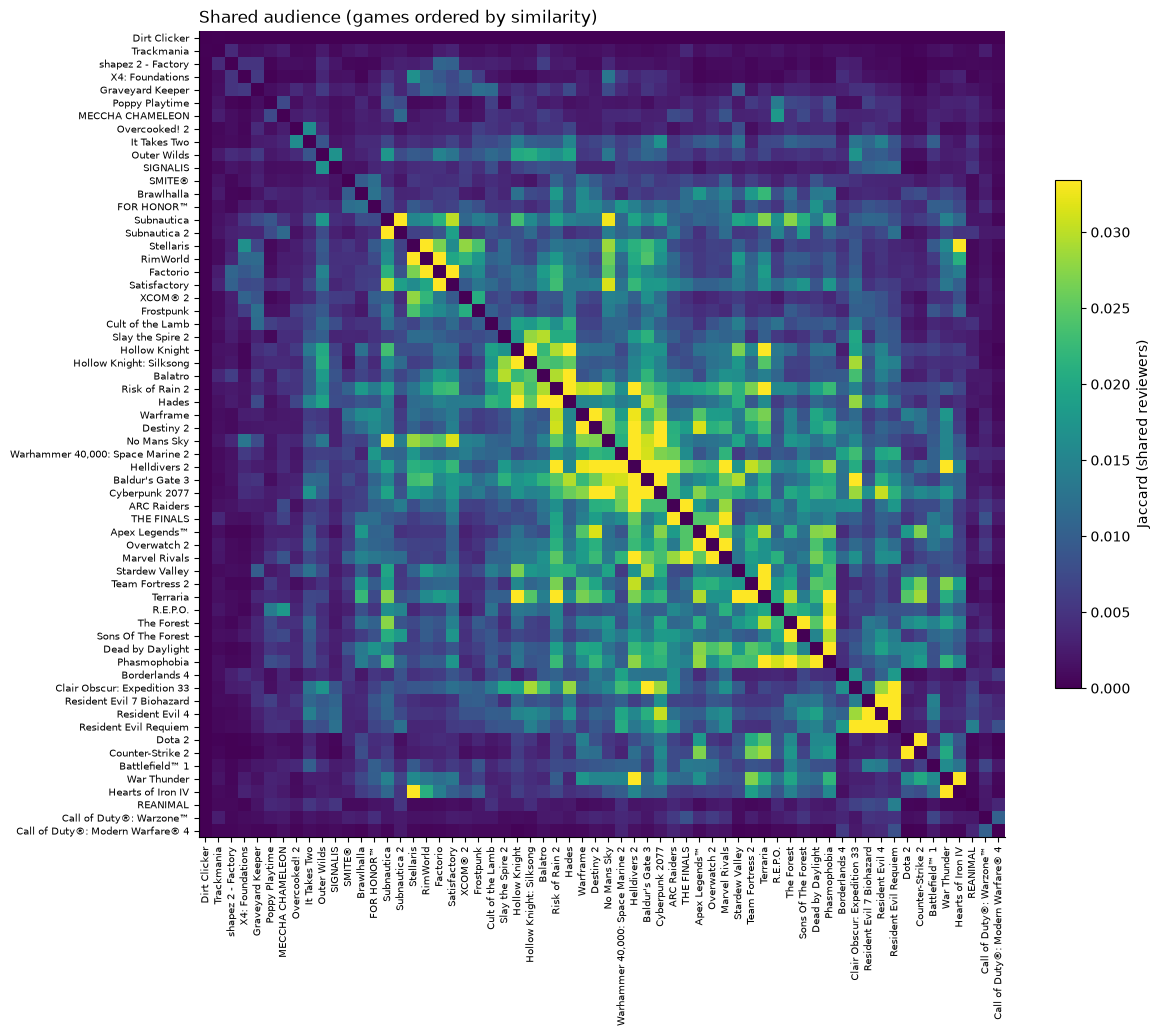

In [10]:
overlap = audience_overlap()
overlap = overlap[overlap["a"].isin(games) & overlap["b"].isin(games)].reset_index(drop=True)
overlap.to_parquet(FEATURES_DIR / "audience_overlap.parquet")
matrix = overlap.pivot(index="a", columns="b", values="jaccard").reindex(index=games, columns=games)
values = matrix.fillna(matrix.T).fillna(0).to_numpy(copy=True)
np.fill_diagonal(values, 0)
matrix = pd.DataFrame(values, index=matrix.index, columns=matrix.columns)
order = matrix.index[leaves_list(linkage(1 - matrix.to_numpy()[np.triu_indices(len(matrix), 1)], "average"))]
shown = matrix.loc[order, order]

fig, ax = plt.subplots(figsize=(13, 11))
image = ax.imshow(shown, cmap="viridis", vmax=np.quantile(shown.to_numpy()[shown.to_numpy() > 0], 0.98))
ax.set_xticks(range(len(shown)), shown.columns.map(names), rotation=90, fontsize=7)
ax.set_yticks(range(len(shown)), shown.index.map(names), fontsize=7)
ax.grid(False)
fig.colorbar(image, ax=ax, label="Jaccard (shared reviewers)", shrink=0.6)
ax.set_title("Shared audience (games ordered by similarity)", loc="left");

communities:
  0: Factorio, Frostpunk, Graveyard Keeper, Hearts of Iron IV, No Mans Sky, RimWorld, Satisfactory, Stellaris, Subnautica, Subnautica 2, War Thunder, X4: Foundations, XCOM® 2, shapez 2 - Factory
  1: Balatro, Cult of the Lamb, Hades, Hollow Knight, Hollow Knight: Silksong, It Takes Two, Outer Wilds, Overcooked! 2, Risk of Rain 2, Slay the Spire 2
  2: Baldur's Gate 3, Cyberpunk 2077, Destiny 2, FOR HONOR™, Helldivers 2, SMITE®, Warframe, Warhammer 40,000: Space Marine 2
  3: ARC Raiders, Borderlands 4, Call of Duty®: Modern Warfare® 4, Call of Duty®: Warzone™, Marvel Rivals, Overwatch 2, THE FINALS, Trackmania
  4: Battlefield™ 1, Dead by Daylight, MECCHA CHAMELEON, Phasmophobia, Poppy Playtime, R.E.P.O., Sons Of The Forest, The Forest
  5: Apex Legends™, Brawlhalla, Counter-Strike 2, Dota 2, Stardew Valley, Team Fortress 2, Terraria
  6: Clair Obscur: Expedition 33, REANIMAL, Resident Evil 4, Resident Evil 7 Biohazard, Resident Evil Requiem, SIGNALIS


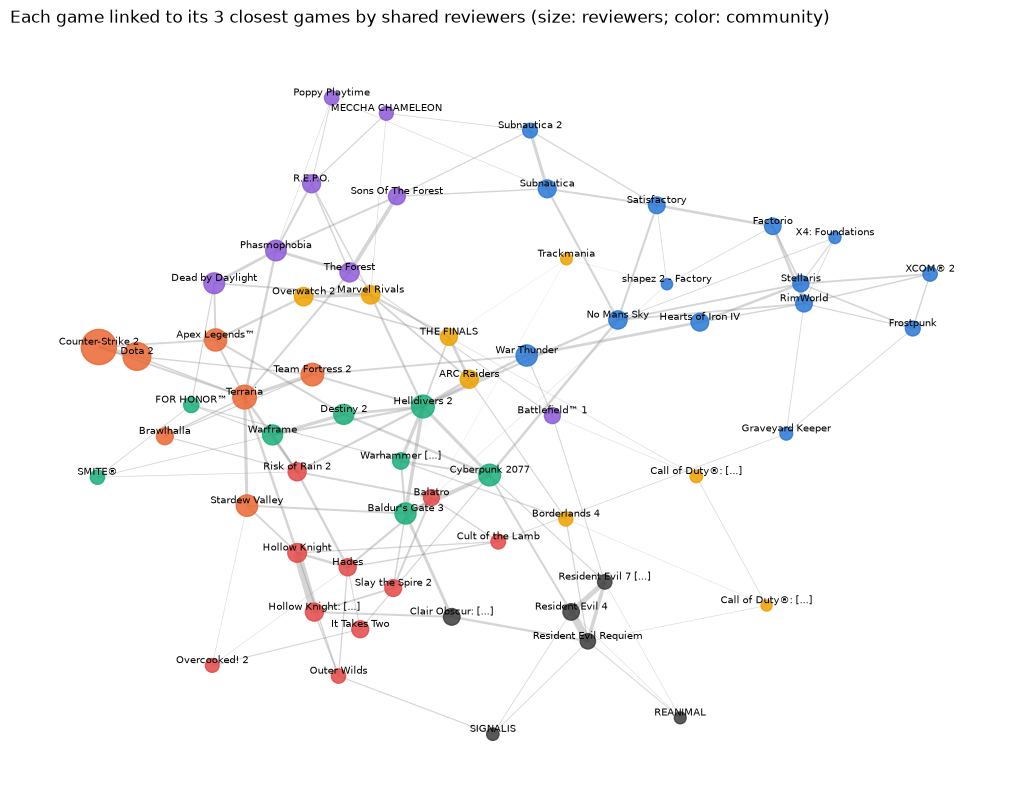

In [11]:
near = neighbours(overlap, top=3)
graph = nx.Graph()
reviewers = pd.concat([overlap.set_index("a")["reviewers_a"], overlap.set_index("b")["reviewers_b"]]).groupby(level=0).first()
big = reviewers.index[reviewers >= 1000]  # tiny games (a few hundred reviewers) have no real neighbours
for r in near[near["appid"].isin(big) & near["other"].isin(big)].itertuples():
    graph.add_edge(r.appid, r.other, weight=r.jaccard / near["jaccard"].max())  # 0..1: pulls against the spread
communities = nx.community.greedy_modularity_communities(graph, weight="weight")
group = {appid: i for i, members in enumerate(communities) for appid in members}
position = nx.spring_layout(graph, weight="weight", seed=0, iterations=300)
palette = ["#2a78d6", "#e34948", "#1baf7a", "#eda100", "#8e5bd8", "#eb6834", "#3c3c3c", "#2bb3c0"]

fig, ax = plt.subplots(figsize=(13, 10))
widths = [6 * graph[u][v]["weight"] for u, v in graph.edges]
nx.draw_networkx_edges(graph, position, ax=ax, width=widths, alpha=0.35, edge_color="#888888")
nx.draw_networkx_nodes(graph, position, ax=ax, node_size=[40 + 600 * np.sqrt(reviewers[n] / reviewers.max()) for n in graph.nodes],
                       node_color=[palette[group[n] % len(palette)] for n in graph.nodes], alpha=0.85)
for n, (x, y) in position.items():
    ax.text(x, y, textwrap.shorten(names.get(n, str(n)), 22), fontsize=7, ha="center", va="bottom")
ax.set_axis_off()
ax.set_title("Each game linked to its 3 closest games by shared reviewers (size: reviewers; color: community)", loc="left")
print("communities:")
for i, members in enumerate(communities):
    print(f"  {i}: " + ", ".join(sorted(names.get(m, str(m)) for m in members)))

In [12]:
pairs = overlap.nlargest(15, "jaccard").assign(game_a=lambda d: d["a"].map(names), game_b=lambda d: d["b"].map(names))
pairs[["game_a", "game_b", "shared", "jaccard", "share_a", "share_b"]].style.format(
    {"shared": "{:,}", "jaccard": "{:.3f}", "share_a": "{:.0%}", "share_b": "{:.0%}"}).hide(axis="index").set_caption(
    "share_a: of game_a's reviewers, how many also reviewed game_b")

game_a,game_b,shared,jaccard,share_a,share_b
Hollow Knight,Hollow Knight: Silksong,"77,452",0.125,20%,25%
Resident Evil 4,Resident Evil Requiem,"30,845",0.108,16%,24%
Resident Evil 7 Biohazard,Resident Evil 4,"19,133",0.075,22%,10%
Dota 2,Counter-Strike 2,"551,230",0.063,22%,8%
Baldur's Gate 3,Cyberpunk 2077,"83,599",0.060,12%,11%
The Forest,Sons Of The Forest,"34,395",0.056,8%,16%
Resident Evil 7 Biohazard,Resident Evil Requiem,"11,053",0.055,13%,9%
Helldivers 2,Baldur's Gate 3,"83,414",0.052,8%,12%
Team Fortress 2,Terraria,"104,089",0.051,11%,9%
Helldivers 2,"Warhammer 40,000: Space Marine 2","55,999",0.049,6%,29%


## 5. Competitor releases

For every game that appeared on Steam while games with a shared audience were already there for at least 90 days: how those 3 closest games' reviews per day and 👍 share changed in the 4 weeks after the appearance (first review) vs the 4 weeks before. There is no control group, so seasonality and sales are mixed in.

In [13]:
series = daily_series(games)
first_review = series.index.to_frame(index=False).groupby("appid")["day"].min()
rows = []
for r in near.itertuples():
    launch, before = first_review[r.appid], first_review[r.other]
    if launch - before >= pd.Timedelta(days=90) and launch > first_review.min() + pd.Timedelta(days=365):
        rows.append({"new_game": r.appid, "appid": r.other, "day": launch, "jaccard": r.jaccard})
releases = pd.DataFrame(rows)
reviews_change = event_study(np.log1p(series["n"]), releases, 28, 28, (-28, -1))
post = reviews_change[reviews_change["offset"].between(0, 27)].groupby("event")["change"].mean()
n_window = event_study(series["n"], releases, 28, 28, (-28, -1))
n_positive = event_study(series["n_positive"], releases, 28, 28, (-28, -1))
both = n_window.assign(n_positive=n_positive["value"], after=n_window["offset"] >= 0).groupby(["event", "after"])[["value", "n_positive"]].sum()
positive = (both["n_positive"] / both["value"]).unstack()
releases["reviews_change"] = np.expm1(post)
releases["positive_change"] = positive[True] - positive[False]
releases["new"] = releases["new_game"].map(names)
releases["neighbour"] = releases["appid"].map(names)
print(f"{len(releases)} release × neighbour pairs; median change in the neighbours' reviews per day: "
      f"{releases['reviews_change'].median():+.0%}, mean 👍 change {releases['positive_change'].mean():+.1%}")
releases.sort_values("jaccard", ascending=False).head(20)[["new", "day", "neighbour", "jaccard", "reviews_change", "positive_change"]].style.format(
    {"day": "{:%Y-%m-%d}", "jaccard": "{:.3f}", "reviews_change": "{:+.0%}", "positive_change": "{:+.1%}"}).hide(axis="index")

97 release × neighbour pairs; median change in the neighbours' reviews per day: +1%, mean 👍 change +0.2%


new,day,neighbour,jaccard,reviews_change,positive_change
Hollow Knight: Silksong,2025-09-04,Hollow Knight,0.125,+172%,-1.2%
Resident Evil Requiem,2026-02-27,Resident Evil 4,0.108,+26%,+13.4%
Resident Evil 4,2023-03-24,Resident Evil 7 Biohazard,0.075,+7%,-0.5%
Counter-Strike 2,2012-05-12,Dota 2,0.063,-40%,-1.4%
Sons Of The Forest,2023-02-23,The Forest,0.056,+19%,-0.9%
Resident Evil Requiem,2026-02-27,Resident Evil 7 Biohazard,0.055,+70%,-0.2%
Helldivers 2,2024-02-08,Baldur's Gate 3,0.052,-21%,-0.1%
"Warhammer 40,000: Space Marine 2",2024-09-05,Helldivers 2,0.049,-27%,+22.0%
Destiny 2,2019-10-01,Warframe,0.048,-46%,+36.3%
Helldivers 2,2024-02-08,Cyberpunk 2077,0.047,+1%,-0.4%


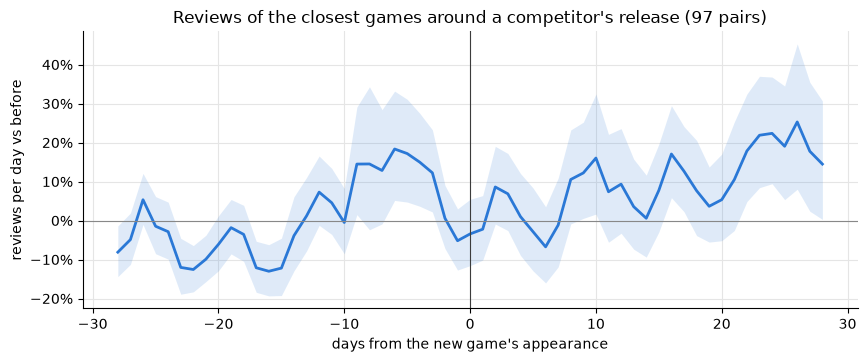

In [14]:
path = reviews_change.groupby("offset")["change"].agg(["mean", "std", "count"])
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(path.index, np.expm1(path["mean"]), color=SERIES_COLOR)
ax.fill_between(path.index, np.expm1(path["mean"] - 1.96 * path["std"] / np.sqrt(path["count"])),
                np.expm1(path["mean"] + 1.96 * path["std"] / np.sqrt(path["count"])), color=SERIES_COLOR, alpha=0.15, linewidth=0)
ax.axvline(0, color="#3c3c3c", linewidth=0.8)
ax.axhline(0, color="#888888", linewidth=0.8)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set(xlabel="days from the new game's appearance", ylabel="reviews per day vs before",
       title=f"Reviews of the closest games around a competitor's release ({len(releases)} pairs)");